In [1]:
import pandas as pd
import matplotlib.pyplot as plt

filename = r"exoplanets_slim_2026-10-15.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"log_orb_sm_axis": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
display(df.dtypes)

(6445, 22)


pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

d = df.dropna(subset=["pl_temp", "pl_orb_semimajor_axis"]).copy()
d["log_pl_temp"] = np.log10(d["pl_temp"])
d["log_orb_sm_axis"] = np.log10(d["pl_orb_semimajor_axis"])

print("dropped rows: ", len(df) - len(d))
print(d["log_pl_temp"].describe())
print(d["log_orb_sm_axis"].value_counts())

dropped rows:  801
count    5644.000000
mean        2.829976
std         0.314648
min         0.170262
25%         2.679428
50%         2.875061
75%         3.038322
max         3.890856
Name: log_pl_temp, dtype: float64
log_orb_sm_axis
-1.221849    21
-1.318759    20
-1.292430    17
-1.301030    17
-1.167491    16
             ..
-0.926648     1
 0.019532     1
-0.981716     1
-1.271322     1
 0.387034     1
Name: count, Length: 3486, dtype: int64


In [3]:
x = d[["log_orb_sm_axis"]]
y = d["log_pl_temp"]

xTrain, xTest, yTrain, yTest = train_test_split(
    x, y, test_size=0.2, random_state=42
)

m1 = LinearRegression().fit(xTrain, yTrain)

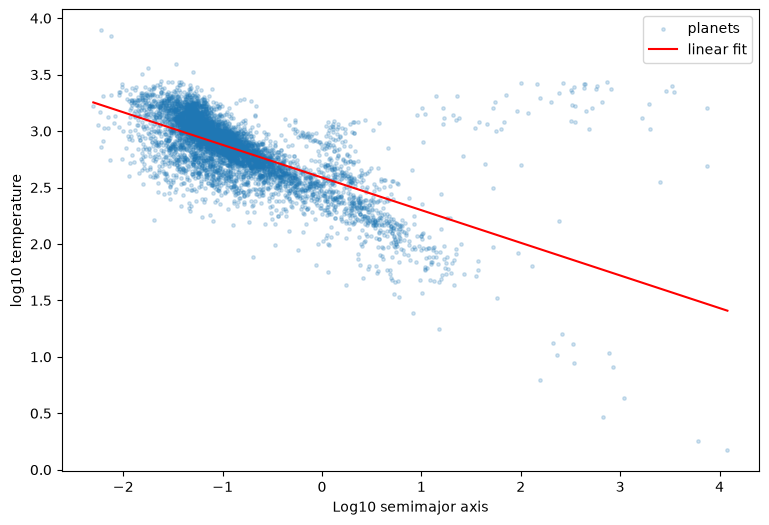

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(d["log_orb_sm_axis"], d["log_pl_temp"], s=6, alpha=0.2, label="planets")

xs = np.linspace(d["log_orb_sm_axis"].min(), d["log_orb_sm_axis"].max(), 100)
ax.plot(xs, m1.predict(pd.DataFrame({"log_orb_sm_axis": xs})), "r", label="linear fit")

ax.set_xlabel("Log10 semimajor axis")
ax.set_ylabel("log10 temperature")
ax.legend()
plt.show()

In [5]:
pred1 = m1.predict(xTest)
print("slope:", m1.coef_[0], "intercept:", m1.intercept_)
print("test R^2:", r2_score(yTest, pred1))
print("test RMSE:", np.sqrt(mean_squared_error(yTest, pred1)))

slope: -0.2891637864783271 intercept: 2.588361124967522
test R^2: 0.4283795622436407
test RMSE: 0.23558123646648169


In [6]:
baseline = np.full(len(yTest), yTrain.mean())
baseline_rmse = np.sqrt(mean_squared_error(yTest, baseline))
print("BASELINE: ", baseline_rmse)

BASELINE:  0.31161654242999126


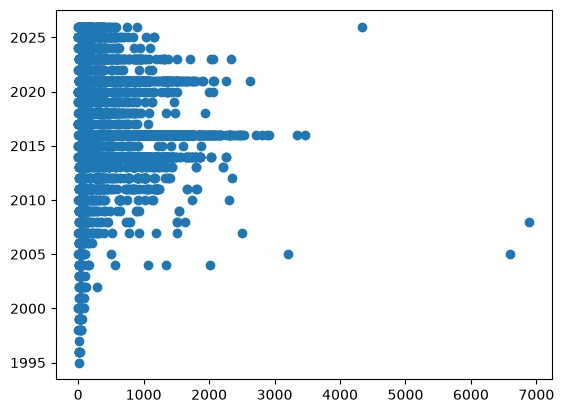

In [7]:
x = d[["sys_dist_e"]]
y = d["disc_year"]

plt.scatter(x, y)
plt.show()